In [ ]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/

cp: cannot stat 'kaggle.json': No such file or directory


In [ ]:
!kaggle datasets download -d raahimrizwan/5-celebrities-face-classification-dataset

Dataset URL: https://www.kaggle.com/datasets/raahimrizwan/5-celebrities-face-classification-dataset
License(s): MIT
 85% 65.0M/76.2M [00:01<00:00, 47.1MB/s]
100% 76.2M/76.2M [00:01<00:00, 42.8MB/s]


In [ ]:
import zipfile
zip_ref = zipfile.ZipFile('/content/5-celebrities-face-classification-dataset.zip', 'r')
zip_ref.extractall('/content')
zip_ref.close()

In [ ]:
import os

# Define the input directory
input_dir = '/content/Celebrity Images'

# Count the number of files in the input data directory
total_files = sum(len(files) for _, _, files in os.walk(input_dir))

# Print the total number of files
print(f"Total number of files in the input data directory: {total_files}")

Total number of files in the input data directory: 271


In [ ]:
import os

# Define the input directory
input_dir = '/content/Celebrity Images'

# Initialize counters and lists
total_files = 0
folders = []

# Walk through the directory structure
for root, dirs, files in os.walk(input_dir):
    # Count the number of files
    total_files += len(files)
    # Collect folder names
    if dirs:
        folders.extend([os.path.join(root, d) for d in dirs])

# Print the total number of files
print(f"Total number of files in the input data directory: {total_files}")

# Print the list of folders
print("Folders in the input data directory:")
for folder in folders:
    print(folder)

Total number of files in the input data directory: 271
Folders in the input data directory:
/content/Celebrity Images/ronaldo
/content/Celebrity Images/messi
/content/Celebrity Images/virat_kohli
/content/Celebrity Images/maria_sharapova
/content/Celebrity Images/shahrukh_khan


In [ ]:
# prompt: add code to rename the images if its extension is not '.png', '.jpg', '.jpeg' from these delete it

import os
import shutil

# Define allowed image extensions
allowed_extensions = ('.png', '.jpg', '.jpeg')

# Iterate through the files in the input directory
for root, _, files in os.walk(input_dir):
    for filename in files:
        base, ext = os.path.splitext(filename)
        filepath = os.path.join(root, filename)

        # Check if the file is an image with an allowed extension
        if ext.lower() in allowed_extensions:
            # Rename the file if necessary (e.g., to ensure lowercase extension)
            new_filename = base + ext.lower()
            new_filepath = os.path.join(root, new_filename)
            if filename != new_filename:
                os.rename(filepath, new_filepath)
                print(f"Renamed '{filename}' to '{new_filename}'")

        # If it's not an allowed image type, delete it
        else:
            try:
                os.remove(filepath)
                print(f"Deleted file: {filename} (invalid extension)")
            except OSError as e:
                print(f"Error deleting {filename}: {e}")

Deleted file: 1669759136_screenshot-2022-11-30-032814.gif (invalid extension)
Deleted file: shahrukh-khan-farah-ki-daawat-167991-600x450_1485251825.webp (invalid extension)


In [ ]:
import os
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.model_selection import train_test_split
import shutil

# Define paths
base_dir = '/content/Celebrity Images'
subset_dir = '/content/Celebrity Images'
train_dir = os.path.join(subset_dir, 'train')
validation_dir = os.path.join(subset_dir, 'validation')

# Create subset directory structure
os.makedirs(train_dir, exist_ok=True)
os.makedirs(validation_dir, exist_ok=True)

# Create train and validation directories for each class
classes = ['messi', 'ronaldo', 'virat_kohli', 'maria_sharapova', 'shahrukh_khan']
for cls in classes:
    os.makedirs(os.path.join(train_dir, cls), exist_ok=True)
    os.makedirs(os.path.join(validation_dir, cls), exist_ok=True)

# Split data into training and validation sets
for cls in classes:
    class_dir = os.path.join(base_dir, cls)
    images = [f for f in os.listdir(class_dir) if os.path.isfile(os.path.join(class_dir, f))]
    train_images, val_images = train_test_split(images, test_size=0.2, random_state=42)

    for img in train_images:
        src = os.path.join(class_dir, img)
        dst = os.path.join(train_dir, cls, img)
        shutil.copyfile(src, dst)

    for img in val_images:
        src = os.path.join(class_dir, img)
        dst = os.path.join(validation_dir, cls, img)
        shutil.copyfile(src, dst)

# Image data generator for training and validation
train_datagen = ImageDataGenerator(rescale=1./255, rotation_range=40, width_shift_range=0.2,
                                   height_shift_range=0.2, shear_range=0.2, zoom_range=0.2,
                                   horizontal_flip=True, fill_mode='nearest')

validation_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(train_dir, target_size=(150, 150),
                                                    batch_size=20, class_mode='categorical')

validation_generator = validation_datagen.flow_from_directory(validation_dir, target_size=(150, 150),
                                                              batch_size=20, class_mode='categorical')

Found 213 images belonging to 5 classes.
Found 56 images belonging to 5 classes.


VGG16

Found 213 images belonging to 5 classes.
Found 56 images belonging to 5 classes.
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/30


/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


 11/100 ━━━━━━━━━━━━━━━━━━━━ 50s 573ms/step - accuracy: 0.2483 - loss: 1.9176

/usr/lib/python3.11/contextlib.py:158: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self.gen.throw(typ, value, traceback)


100/100 ━━━━━━━━━━━━━━━━━━━━ 28s 170ms/step - accuracy: 0.2947 - loss: 1.8599 - val_accuracy: 0.2500 - val_loss: 1.5768
Epoch 2/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 22s 30ms/step - accuracy: 0.2452 - loss: 1.7757 - val_accuracy: 0.3036 - val_loss: 1.5372
Epoch 3/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - accuracy: 0.2528 - loss: 1.7941 - val_accuracy: 0.3393 - val_loss: 1.5130
Epoch 4/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 5s 24ms/step - accuracy: 0.2503 - loss: 1.7579 - val_accuracy: 0.3929 - val_loss: 1.4921
Epoch 5/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - accuracy: 0.2939 - loss: 1.5781 - val_accuracy: 0.3750 - val_loss: 1.4681
Epoch 6/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 5s 28ms/step - accuracy: 0.2948 - loss: 1.6301 - val_accuracy: 0.3929 - val_loss: 1.4484
Epoch 7/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 10s 20ms/step - accuracy: 0.3007 - loss: 1.5801 - val_accuracy: 0.4107 - val_loss: 1.4344
Epoch 8/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 6s 28ms/step - accuracy: 0.3043 - loss: 1.5413 - val_accuracy: 0

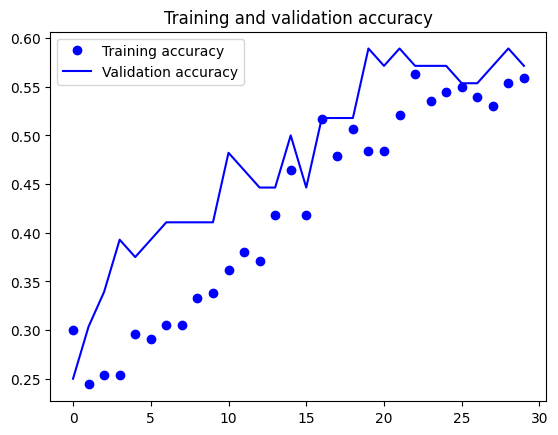

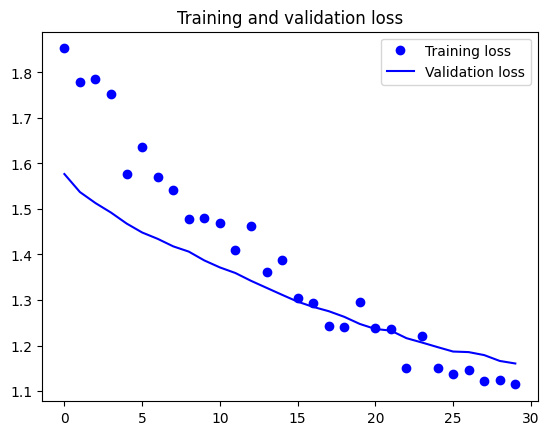

In [ ]:
import os
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import VGG16
from tensorflow.keras import layers, models, optimizers
from sklearn.model_selection import train_test_split
import shutil
import matplotlib.pyplot as plt

# Define paths
base_dir = '/content/Celebrity Images'
subset_dir = '/content/Celebrity Images'
train_dir = os.path.join(subset_dir, 'train')
validation_dir = os.path.join(subset_dir, 'validation')

# Create subset directory structure
os.makedirs(train_dir, exist_ok=True)
os.makedirs(validation_dir, exist_ok=True)

# Create train and validation directories for each class
classes = ['messi', 'ronaldo', 'virat_kohli', 'maria_sharapova', 'shahrukh_khan']
for cls in classes:
    os.makedirs(os.path.join(train_dir, cls), exist_ok=True)
    os.makedirs(os.path.join(validation_dir, cls), exist_ok=True)

# Split data into training and validation sets
for cls in classes:
    class_dir = os.path.join(base_dir, cls)
    images = [f for f in os.listdir(class_dir) if os.path.isfile(os.path.join(class_dir, f))]
    train_images, val_images = train_test_split(images, test_size=0.2, random_state=42)

    for img in train_images:
        src = os.path.join(class_dir, img)
        dst = os.path.join(train_dir, cls, img)
        shutil.copyfile(src, dst)

    for img in val_images:
        src = os.path.join(class_dir, img)
        dst = os.path.join(validation_dir, cls, img)
        shutil.copyfile(src, dst)

# Image data generator for training and validation
train_datagen = ImageDataGenerator(rescale=1./255, rotation_range=40, width_shift_range=0.2,
                                   height_shift_range=0.2, shear_range=0.2, zoom_range=0.2,
                                   horizontal_flip=True, fill_mode='nearest')

validation_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(train_dir, target_size=(150, 150),
                                                    batch_size=20, class_mode='categorical')

validation_generator = validation_datagen.flow_from_directory(validation_dir, target_size=(150, 150),
                                                              batch_size=20, class_mode='categorical')

# Load the VGG16 model
conv_base = VGG16(weights='imagenet', include_top=False, input_shape=(150, 150, 3))

# Freeze the convolutional base
conv_base.trainable = False

# Build the model
model = models.Sequential()
model.add(conv_base)
model.add(layers.Flatten())
model.add(layers.Dense(256, activation='relu'))
model.add(layers.Dropout(0.5))
model.add(layers.Dense(5, activation='softmax'))  # 5 classes

# Compile the model
model.compile(loss='categorical_crossentropy', optimizer=optimizers.RMSprop(learning_rate=2e-5), metrics=['accuracy'])

# Train the model
history = model.fit(train_generator, steps_per_epoch=100, epochs=30,
                    validation_data=validation_generator, validation_steps=50)

# Plot training and validation accuracy and loss
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(len(acc))

plt.plot(epochs, acc, 'bo', label='Training accuracy')
plt.plot(epochs, val_acc, 'b', label='Validation accuracy')
plt.title('Training and validation accuracy')
plt.legend()

plt.figure()

plt.plot(epochs, loss, 'bo', label='Training loss')
plt.plot(epochs, val_loss, 'b', label='Validation loss')
plt.title('Training and validation loss')
plt.legend()

plt.show()

In [ ]:
# prompt: save the model

# Save the model
model.save('VGG16.h5')

# Download the saved model
from google.colab import files
files.download('VGG16.h5')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
#7. Implement Face Detection and Recognition

#To recognize faces in new images, implement face detection using OpenCV and predict using the trained model:
import tensorflow as tf
import cv2
import numpy as np
from tensorflow.keras.preprocessing.image import img_to_array

# Load the trained model
model = tf.keras.models.load_model('/content/VGG16.h5')

# Create a dictionary mapping class indices to names
# label_map = train_data.class_indices  # Assuming you have train_data available
# label_dict = {v: k for k, v in label_map.items()}
# Since 'train_data' is not defined in this scope, let's manually define the dictionary
label_dict = {0: 'messi', 1: 'ronaldo', 2: 'virat_kohli', 3: 'maria_sharapova', 4: 'shahrukh_khan'}


# Load the pre-trained face detection model from OpenCV
face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')

def detect_faces(image):
    """Detect faces in an image using OpenCV's Haar Cascade classifier."""
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5, minSize=(30, 30))
    return faces

def recognize_faces(image, faces, threshold=0.8):
    """Recognize faces in an image given the bounding boxes."""
    recognized_faces = []
    for (x, y, w, h) in faces:
        face_img = image[y:y+h, x:x+w]
        # Resize to the expected input shape of the model (150, 150)
        face_img = cv2.resize(face_img, (150, 150))
        face_array = img_to_array(face_img) / 255.0
        face_array = np.expand_dims(face_array, axis=0)
        prediction = model.predict(face_array)
        predicted_label = np.argmax(prediction)
        confidence = np.max(prediction)
        recognized_faces.append((x, y, w, h, label_dict[predicted_label], confidence))
    return recognized_faces

def process_image(image_path, threshold=0.8):
    """Process an image to detect and recognize faces."""
    image = cv2.imread(image_path)
    faces = detect_faces(image)
    recognized_faces = recognize_faces(image, faces)
    for (x, y, w, h, name, confidence) in recognized_faces:
        cv2.rectangle(image, (x, y), (x+w, y+h), (0, 255, 0), 6)
        cv2.putText(image, f'{name} ({confidence:.2f})', (x, y-10), cv2.FONT_HERSHEY_SIMPLEX, 1.5, (0, 255, 0), 5)
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(10, 6))
    plt.imshow(image_rgb)
    plt.axis('off')
    plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
threshold = 0.8
image_paths = ['/content/drive/MyDrive/Colab Notebooks/ML/test11.png']
for image_path in image_paths:
  process_image(image_path, threshold)

AttributeError: 'RexNet' object has no attribute 'predict'

RXNET-150

In [ ]:
!pip install ultralytics
!pip install torchmetrics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 911.4/911.4 kB 22.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 927.3/927.3 kB 16.4 MB/s eta 0:00:00


/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model.safetensors:   0%|          | 0.00/39.2M [00:00<?, ?B/s]

Training Epoch 1/10: 100%|██████████| 7/7 [00:07<00:00,  1.13s/it]


Epoch 1 - Train Loss: 2.415, Accuracy: 0.380, F1 Score: 0.394


Validation Epoch 1/10: 100%|██████████| 2/2 [00:01<00:00,  1.75it/s]


Epoch 1 - Val Loss: 1.623, Accuracy: 0.589, F1 Score: 0.583
Model saved with validation loss: 3.246


... (20 outputs left out)

Training Epoch 7/10: 100%|██████████| 7/7 [00:05<00:00,  1.20it/s]


Epoch 7 - Train Loss: 0.001, Accuracy: 1.000, F1 Score: 1.000


Validation Epoch 7/10: 100%|██████████| 2/2 [00:01<00:00,  1.58it/s]


Epoch 7 - Val Loss: 0.929, Accuracy: 0.786, F1 Score: 0.797
Training stopped as validation loss did not improve for 5 epochs.


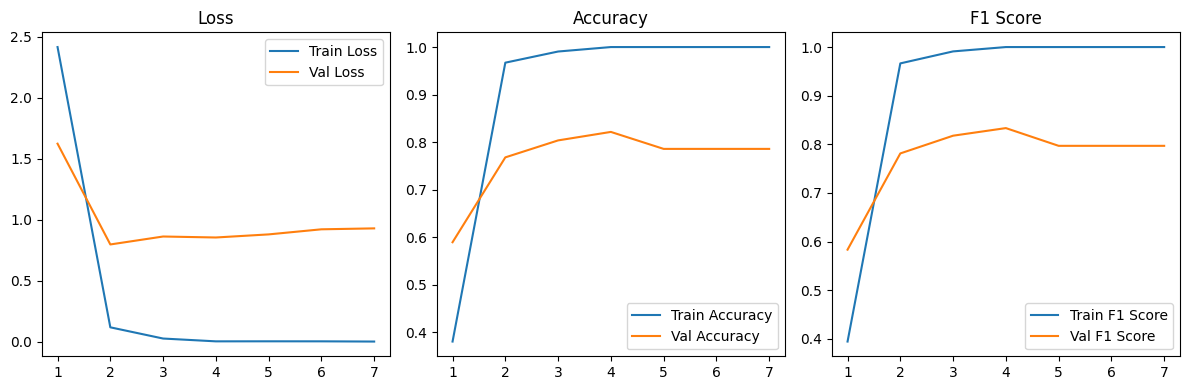

In [ ]:
import os
import torch
import torchmetrics
from tqdm import tqdm
from torchvision import transforms, datasets
from torch.utils.data import DataLoader
import timm
import matplotlib.pyplot as plt

# Define paths and classes
save_prefix = "Attendance"
save_dir = "saved_models"
os.makedirs(save_dir, exist_ok=True)

classes = ["messi", "ronaldo", "virat_kohli", "maria_sharapova", "shahrukh_khan"]

# Create model
model = timm.create_model("rexnet_150", pretrained=True, num_classes=len(classes))

# Define device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Setup training configuration
def train_setup(model):
    model = model.to(device).train()
    epochs = 10
    loss_fn = torch.nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=3e-4)
    return model, epochs, device, loss_fn, optimizer

model, epochs, device, loss_fn, optimizer = train_setup(model)

# Define metrics
f1_score = torchmetrics.F1Score(task="multiclass", num_classes=len(classes)).to(device)

# Function to move batch to device
def to_device(batch, device):
    return batch[0].to(device), batch[1].to(device)

# Function to calculate metrics
def calculate_metrics(model, ims, gts, loss_fn):
    preds = model(ims)
    loss = loss_fn(preds, gts)
    accuracy = (torch.argmax(preds, dim=1) == gts).sum().item()
    f1 = f1_score(preds, gts)
    return loss, accuracy, f1

# Training and validation loop with metric tracking
def train_and_validate(model, train_loader, val_loader, epochs, loss_fn, optimizer):
    best_loss = float('inf')
    patience, not_improved = 5, 0

    # Lists to store metrics
    train_losses, val_losses = [], []
    train_accuracies, val_accuracies = [], []
    train_f1s, val_f1s = [], []

    for epoch in range(epochs):
        model.train()
        epoch_loss, epoch_acc, epoch_f1 = 0, 0, 0

        # Training loop
        for batch in tqdm(train_loader, desc=f"Training Epoch {epoch + 1}/{epochs}"):
            ims, gts = to_device(batch, device)
            optimizer.zero_grad()
            loss, acc, f1 = calculate_metrics(model, ims, gts, loss_fn)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()
            epoch_acc += acc
            epoch_f1 += f1.item()

        # Logging training metrics
        num_batches = len(train_loader)
        train_losses.append(epoch_loss / num_batches)
        train_accuracies.append(epoch_acc / len(train_loader.dataset))
        train_f1s.append(epoch_f1 / num_batches)
        print(f"Epoch {epoch + 1} - Train Loss: {train_losses[-1]:.3f}, "
              f"Accuracy: {train_accuracies[-1]:.3f}, "
              f"F1 Score: {train_f1s[-1]:.3f}")

        # Validation loop
        model.eval()
        val_epoch_loss, val_epoch_acc, val_epoch_f1 = 0, 0, 0
        with torch.no_grad():
            for batch in tqdm(val_loader, desc=f"Validation Epoch {epoch + 1}/{epochs}"):
                ims, gts = to_device(batch, device)
                loss, acc, f1 = calculate_metrics(model, ims, gts, loss_fn)
                val_epoch_loss += loss.item()
                val_epoch_acc += acc
                val_epoch_f1 += f1.item()

        # Logging validation metrics
        num_batches = len(val_loader)
        val_losses.append(val_epoch_loss / num_batches)
        val_accuracies.append(val_epoch_acc / len(val_loader.dataset))
        val_f1s.append(val_epoch_f1 / num_batches)
        print(f"Epoch {epoch + 1} - Val Loss: {val_losses[-1]:.3f}, "
              f"Accuracy: {val_accuracies[-1]:.3f}, "
              f"F1 Score: {val_f1s[-1]:.3f}")

        # Check for improvement
        if val_epoch_loss < best_loss:
            best_loss = val_epoch_loss
            torch.save(model.state_dict(), f"{save_dir}/{save_prefix}_best_model.pth")
            print(f"Model saved with validation loss: {best_loss:.3f}")
            not_improved = 0
        else:
            not_improved += 1
            if not_improved >= patience:
                print(f"Training stopped as validation loss did not improve for {patience} epochs.")
                break

    # Plotting the metrics
    epochs_range = range(1, len(train_losses) + 1)

    plt.figure(figsize=(12, 4))
    plt.subplot(1, 3, 1)
    plt.plot(epochs_range, train_losses, label='Train Loss')
    plt.plot(epochs_range, val_losses, label='Val Loss')
    plt.legend(loc='best')
    plt.title('Loss')

    plt.subplot(1, 3, 2)
    plt.plot(epochs_range, train_accuracies, label='Train Accuracy')
    plt.plot(epochs_range, val_accuracies, label='Val Accuracy')
    plt.legend(loc='best')
    plt.title('Accuracy')

    plt.subplot(1, 3, 3)
    plt.plot(epochs_range, train_f1s, label='Train F1 Score')
    plt.plot(epochs_range, val_f1s, label='Val F1 Score')
    plt.legend(loc='best')
    plt.title('F1 Score')

    plt.tight_layout()
    plt.show()

# Define data transforms
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Load datasets
train_dataset = datasets.ImageFolder(os.path.join(train_dir), transform=transform)
val_dataset = datasets.ImageFolder(os.path.join(validation_dir), transform=transform)

# Create data loaders
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

# Train and validate the model
train_and_validate(model, train_loader, val_loader, epochs, loss_fn, optimizer)

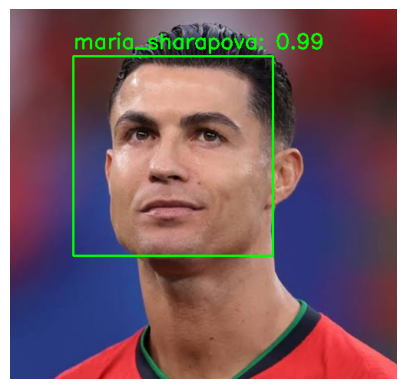

In [ ]:
# prompt: Give me code for face recoginition for this model /content/saved_models/Attendance_best_model.pth

import torch
import cv2
import matplotlib.pyplot as plt
from torchvision import transforms
from PIL import Image

# Load the saved model
model = timm.create_model("rexnet_150", num_classes=5) # 5 classes
model.load_state_dict(torch.load('/content/saved_models/Attendance_best_model.pth'))
model.eval()

# Define device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

# Define image transformations
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Load the pre-trained face detection model from OpenCV
face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')

# Class labels
classes = ["messi", "ronaldo", "virat_kohli", "maria_sharapova", "shahrukh_khan"]

def recognize_face(image_path):
    img = cv2.imread(image_path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    faces = face_cascade.detectMultiScale(gray, 1.1, 4)

    for (x, y, w, h) in faces:
        face_img = img[y:y+h, x:x+w]
        pil_image = Image.fromarray(cv2.cvtColor(face_img, cv2.COLOR_BGR2RGB))
        input_tensor = transform(pil_image).unsqueeze(0).to(device)

        with torch.no_grad():
            output = model(input_tensor)
            _, predicted = torch.max(output, 1)
            predicted_class = classes[predicted.item()]
            confidence = torch.softmax(output, dim=1)[0][predicted.item()].item()


        cv2.rectangle(img, (x, y), (x + w, y + h), (0, 255, 0), 2)
        cv2.putText(img, f"{predicted_class}: {confidence:.2f}", (x, y - 10),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 255, 0), 2)

    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.axis('off')
    plt.show()


# Example usage
#recognize_face('/content/Celebrity Images/train/maria_sharapova/image_17.jpg') # Replace with your image path
recognize_face('/content/drive/MyDrive/Colab Notebooks/ML/test1.PNG') # Replace with your image path



YOLO RXNET

In [ ]:
from pathlib import Path
import requests

# Define the output directory
output_dir = Path("/kaggle/working/yolov8x")
output_dir.mkdir(parents=True, exist_ok=True)  # Create the directory if it doesn't exist

# Define the download URL and save path
url = "https://github.com/ultralytics/assets/releases/download/v8.3.0/yolov8x.pt"
model_path = output_dir / "yolov8x.pt"

# Download the file
response = requests.get(url)
with open(model_path, "wb") as f:
    f.write(response.content)

print(f"Model downloaded to {model_path}")



Model downloaded to /kaggle/working/yolov8x/yolov8x.pt


In [ ]:
output_path = "/kaggle/working/yolov8x"  # Change to writable directory
Path(output_path).mkdir(parents=True, exist_ok=True)


In [ ]:
import os

if os.path.exists(model_path):
    print(f"Model file exists at {model_path}")
else:
    print("Model download failed!")


Model file exists at /kaggle/working/yolov8x/yolov8x.pt


In [ ]:
import os
import torch
import torchmetrics
from tqdm import tqdm
from torchvision import transforms
from torch.utils.data import DataLoader, Dataset
import timm
import matplotlib.pyplot as plt
from ultralytics import YOLO
from PIL import Image


In [ ]:
# Define paths and classes
save_prefix = "imageclassification"
save_dir = "saved_models"
os.makedirs(save_dir, exist_ok=True)

classes = ["messi", "ronaldo", "virat_kohli", "maria_sharapova", "shahrukh_khan"]
num_classes = len(classes)
train_dir = '/content/Celebrity Images'
validation_dir = '/content/Celebrity Images'

# Load YOLO model
yolo_model_path = '/kaggle/working/yolov8x/yolov8x.pt'
yolo_model = YOLO(yolo_model_path)

In [ ]:
# Function to detect and crop images using YOLO
def detect_and_crop(image_path, yolo_model):
    results = yolo_model(image_path)
    img = Image.open(image_path).convert("RGB")  # Ensure image is in RGB mode
    if results and results[0].boxes:  # Check if any objects are detected
        box = results[0].boxes[0]  # Use only the first detected box
        x1, y1, x2, y2 = map(int, box.xyxy[0])  # Convert tensor to integer
        cropped_img = img.crop((x1, y1, x2, y2)).resize((224, 224))
        return cropped_img
    else:
        # If no objects are detected, return the whole image resized
        return img.resize((224, 224))


In [ ]:
# Define data transforms
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [ ]:
# Custom dataset class to handle cropped images
class CroppedImageDataset(Dataset):
    def __init__(self, image_paths, transform=None):
        self.image_paths = image_paths
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        crop = detect_and_crop(img_path, yolo_model)
        if self.transform:
            crop = self.transform(crop)
        # Generate a target label based on the directory structure
        label = classes.index(os.path.basename(os.path.dirname(img_path)))
        return crop, label

In [ ]:
# Create RexNet model
model = timm.create_model("rexnet_150", pretrained=True, num_classes=num_classes)

# Define device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
# Setup training configuration
def train_setup(model):
    model = model.to(device).train()
    epochs = 10
    loss_fn = torch.nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=3e-4)
    return model, epochs, device, loss_fn, optimizer

model, epochs, device, loss_fn, optimizer = train_setup(model)

In [ ]:
# Define metrics
f1_score = torchmetrics.F1Score(task="multiclass", num_classes=num_classes).to(device)

In [ ]:
# Function to move batch to device
def to_device(batch, device):
    return batch[0].to(device), batch[1].to(device)

# Function to calculate metrics
def calculate_metrics(model, ims, gts, loss_fn):
    preds = model(ims)
    # Ensure target labels are within the valid range
    if gts.max() >= num_classes or gts.min() < 0:
        raise ValueError(f"Target {gts.max()} is out of bounds for {num_classes} classes.")
    loss = loss_fn(preds, gts)
    accuracy = (torch.argmax(preds, dim=1) == gts).sum().item()
    f1 = f1_score(preds, gts)
    return loss, accuracy, f1

In [ ]:

# Training and validation loop with metric tracking
def train_and_validate(model, train_loader, val_loader, epochs, loss_fn, optimizer):
    best_loss = float('inf')
    patience, not_improved = 5, 0

    # Lists to store metrics
    train_losses, val_losses = [], []
    train_accuracies, val_accuracies = [], []
    train_f1s, val_f1s = [], []

    for epoch in range(epochs):
        model.train()
        epoch_loss, epoch_acc, epoch_f1 = 0, 0, 0

        # Training loop
        for batch in tqdm(train_loader, desc=f"Training Epoch {epoch + 1}/{epochs}"):
            ims, gts = to_device(batch, device)
            optimizer.zero_grad()
            try:
                loss, acc, f1 = calculate_metrics(model, ims, gts, loss_fn)
                loss.backward()
                optimizer.step()
                epoch_loss += loss.item()
                epoch_acc += acc
                epoch_f1 += f1.item()
            except ValueError as e:
                print(f"Error: {e}. Skipping this batch.")

        # Logging training metrics
        num_batches = len(train_loader)
        train_losses.append(epoch_loss / num_batches)
        train_accuracies.append(epoch_acc / len(train_loader.dataset))
        train_f1s.append(epoch_f1 / num_batches)
        print(f"Epoch {epoch + 1} - Train Loss: {train_losses[-1]:.3f}, "
              f"Accuracy: {train_accuracies[-1]:.3f}, "
              f"F1 Score: {train_f1s[-1]:.3f}")

        # Validation loop
        model.eval()
        val_epoch_loss, val_epoch_acc, val_epoch_f1 = 0, 0, 0
        with torch.no_grad():
            for batch in tqdm(val_loader, desc=f"Validation Epoch {epoch + 1}/{epochs}"):
                ims, gts = to_device(batch, device)
                try:
                    loss, acc, f1 = calculate_metrics(model, ims, gts, loss_fn)
                    val_epoch_loss += loss.item()
                    val_epoch_acc += acc
                    val_epoch_f1 += f1.item()
                except ValueError as e:
                    print(f"Error: {e}. Skipping this batch.")

        # Logging validation metrics
        num_batches = len(val_loader)
        val_losses.append(val_epoch_loss / num_batches)
        val_accuracies.append(val_epoch_acc / len(val_loader.dataset))
        val_f1s.append(val_epoch_f1 / num_batches)
        print(f"Epoch {epoch + 1} - Val Loss: {val_losses[-1]:.3f}, "
              f"Accuracy: {val_accuracies[-1]:.3f}, "
              f"F1 Score: {val_f1s[-1]:.3f}")

        # Check for improvement
        if val_epoch_loss < best_loss:
            best_loss = val_epoch_loss
            torch.save(model.state_dict(), f"{save_dir}/{save_prefix}_best_model.pth")
            print(f"Model saved with validation loss: {best_loss:.3f}")
            not_improved = 0
        else:
            not_improved += 1
            if not_improved >= patience:
                print(f"Training stopped as validation loss did not improve for {patience} epochs.")
                break



In [ ]:
transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])



In [ ]:
from re import VERBOSE
# Load training and validation datasets
train_image_paths = [os.path.join(train_dir, cls, img) for cls in classes for img in os.listdir(os.path.join(train_dir, cls))]
val_image_paths = [os.path.join(validation_dir, cls, img) for cls in classes for img in os.listdir(os.path.join(validation_dir, cls))]

train_dataset = CroppedImageDataset(train_image_paths, transform=transform)
val_dataset = CroppedImageDataset(val_image_paths, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

# Train and validate the model
train_and_validate(model, train_loader, val_loader, epochs, loss_fn, optimizer)

Training Epoch 1/10:   0%|          | 0/9 [00:00<?, ?it/s]


image 1/1 /content/Celebrity Images/maria_sharapova/Maria+Sharapova+7.jpg: 640x512 1 person, 66.3ms
Speed: 3.1ms preprocess, 66.3ms inference, 679.6ms postprocess per image at shape (1, 3, 640, 512)

image 1/1 /content/Celebrity Images/ronaldo/cristianoronaldo1406.jpg: 640x640 7 persons, 1 tie, 62.4ms
Speed: 3.1ms preprocess, 62.4ms inference, 1.7ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /content/Celebrity Images/shahrukh_khan/156656_2.jpg: 512x640 1 person, 1 chair, 50.2ms
Speed: 2.2ms preprocess, 50.2ms inference, 1.6ms postprocess per image at shape (1, 3, 512, 640)

image 1/1 /content/Celebrity Images/ronaldo/885.jpg: 640x544 1 person, 49.5ms
Speed: 3.3ms preprocess, 49.5ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 544)

image 1/1 /content/Celebrity Images/ronaldo/wp8147590.jpg: 480x640 1 person, 103.4ms
Speed: 2.5ms preprocess, 103.4ms inference, 1.3ms postprocess per image at shape (1, 3, 480, 640)

image 1/1 /content/Celebrity Images/shahru

Training Epoch 1/10:  11%|█         | 1/9 [00:05<00:40,  5.10s/it]


image 1/1 /content/Celebrity Images/ronaldo/187520692_9ce0e1e0a5_c.jpg: 480x640 1 person, 40.3ms
Speed: 2.3ms preprocess, 40.3ms inference, 1.8ms postprocess per image at shape (1, 3, 480, 640)

image 1/1 /content/Celebrity Images/shahrukh_khan/05e8ecb0248f2138b461c5abfe09e11c.jpg: 640x544 1 person, 47.6ms
Speed: 2.3ms preprocess, 47.6ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 544)

image 1/1 /content/Celebrity Images/shahrukh_khan/com_png_.png: 640x640 1 person, 50.2ms
Speed: 2.3ms preprocess, 50.2ms inference, 9.0ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /content/Celebrity Images/ronaldo/daqrzlg-38927a4c-3e60-479f-9408-9a3d7fd1abbc.jpg_token=eyJ0eXAiOiJKV1QiLCJhbGciOiJIUzI1NiJ9.eyJzdWIiOiJ1cm46YXBwOjdlMGQxODg5ODIyNjQzNzNhNWYwZDQxNWVhMGQyNmUwIiwiaXNzIjoidXJuOmFw.jpg: 640x640 1 person, 50.8ms
Speed: 2.5ms preprocess, 50.8ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /content/Celebrity Images/shahrukh_khan/HD-wall

Training Epoch 1/10:  22%|██▏       | 2/9 [00:08<00:26,  3.84s/it]


image 1/1 /content/Celebrity Images/messi/12b7c7b1-7214-4258-92f2-db045de98806.jpg: 448x640 1 person, 37.4ms
Speed: 2.1ms preprocess, 37.4ms inference, 2.4ms postprocess per image at shape (1, 3, 448, 640)

image 1/1 /content/Celebrity Images/messi/Lionel_20Messi.jpg: 640x640 1 person, 50.8ms
Speed: 3.0ms preprocess, 50.8ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /content/Celebrity Images/virat_kohli/virat-kohli-1.png: 640x608 1 person, 50.4ms
Speed: 3.1ms preprocess, 50.4ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 608)

image 1/1 /content/Celebrity Images/ronaldo/cristiano-ronaldo-real-madrid-2D5X5YD.jpg: 640x448 1 person, 1 traffic light, 35.2ms
Speed: 2.5ms preprocess, 35.2ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 448)

image 1/1 /content/Celebrity Images/ronaldo/7c36815433efb7a8adc6c4ab6af2d117.jpg: 640x480 1 person, 37.8ms
Speed: 2.2ms preprocess, 37.8ms inference, 1.3ms postprocess per image at shape (1,

... (397 outputs left out)


image 1/1 /content/Celebrity Images/shahrukh_khan/shah-rukh-khan__64057.1572784201.jpg: 640x480 1 person, 41.3ms
Speed: 2.8ms preprocess, 41.3ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 480)

image 1/1 /content/Celebrity Images/shahrukh_khan/shah-rukh-khan (2).jpg: 384x640 1 person, 32.7ms
Speed: 2.5ms preprocess, 32.7ms inference, 1.2ms postprocess per image at shape (1, 3, 384, 640)

image 1/1 /content/Celebrity Images/shahrukh_khan/com_png_.png: 640x640 1 person, 56.6ms
Speed: 3.8ms preprocess, 56.6ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /content/Celebrity Images/shahrukh_khan/45011024.jpg: 416x640 1 person, 40.8ms
Speed: 2.9ms preprocess, 40.8ms inference, 1.2ms postprocess per image at shape (1, 3, 416, 640)

image 1/1 /content/Celebrity Images/shahrukh_khan/shahrukhkhan-155.jpg: 640x640 1 person, 1 tie, 56.9ms
Speed: 3.7ms preprocess, 56.9ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /cont

Validation Epoch 10/10: 100%|██████████| 9/9 [00:27<00:00,  3.10s/it]

Epoch 10 - Val Loss: 0.000, Accuracy: 1.000, F1 Score: 1.000


Model saved with validation loss: 0.001


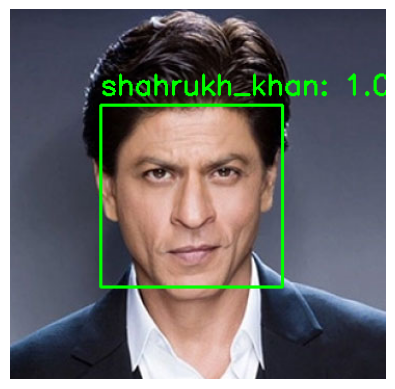

In [ ]:
# prompt: Give me code for face recoginition for this model /content/saved_models/Attendance_best_model.pth

import torch
import cv2
import matplotlib.pyplot as plt
from torchvision import transforms
from PIL import Image

# Load the saved model
model = timm.create_model("rexnet_150", num_classes=5) # 5 classes
model.load_state_dict(torch.load('/content/saved_models/imageclassification_best_model.pth'))
model.eval()

# Define device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

# Define image transformations
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Load the pre-trained face detection model from OpenCV
face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')

# Class labels
classes = ["messi", "ronaldo", "virat_kohli", "maria_sharapova", "shahrukh_khan"]

def recognize_face(image_path):
    img = cv2.imread(image_path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    faces = face_cascade.detectMultiScale(gray, 1.1, 4)

    for (x, y, w, h) in faces:
        face_img = img[y:y+h, x:x+w]
        pil_image = Image.fromarray(cv2.cvtColor(face_img, cv2.COLOR_BGR2RGB))
        input_tensor = transform(pil_image).unsqueeze(0).to(device)

        with torch.no_grad():
            output = model(input_tensor)
            _, predicted = torch.max(output, 1)
            predicted_class = classes[predicted.item()]
            confidence = torch.softmax(output, dim=1)[0][predicted.item()].item()


        cv2.rectangle(img, (x, y), (x + w, y + h), (0, 255, 0), 2)
        cv2.putText(img, f"{predicted_class}: {confidence:.2f}", (x, y - 10),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 255, 0), 2)

    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.axis('off')
    plt.show()


# Example usage
recognize_face('/content/drive/MyDrive/Colab Notebooks/ML/test2.PNG') # Replace with your image path

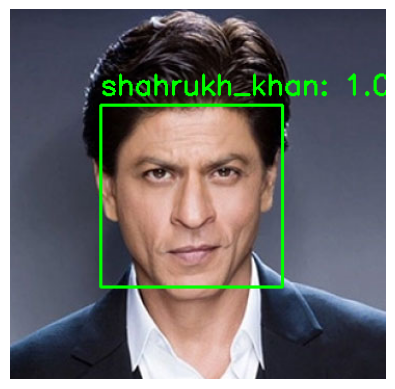

In [ ]:
recognize_face('/content/drive/MyDrive/Colab Notebooks/ML/test2.PNG') # Replace with your image path

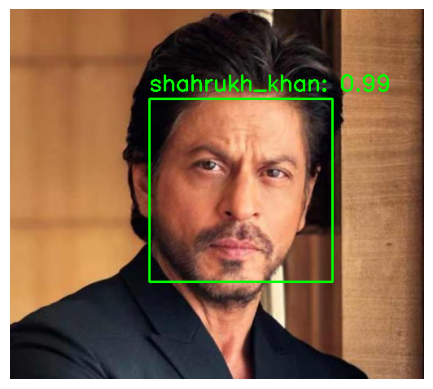

In [ ]:
recognize_face('/content/drive/MyDrive/Colab Notebooks/ML/test3.PNG') # Replace with your image path

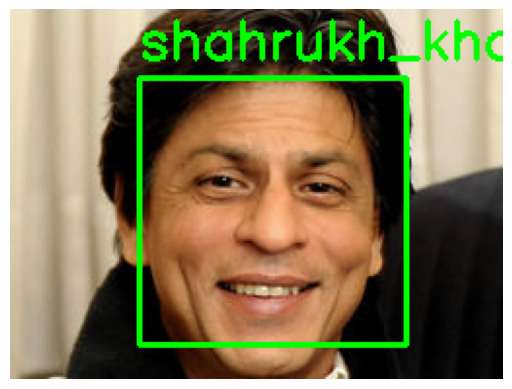

In [ ]:
recognize_face('/content/drive/MyDrive/Colab Notebooks/ML/test4.jpg') # Replace with your image path

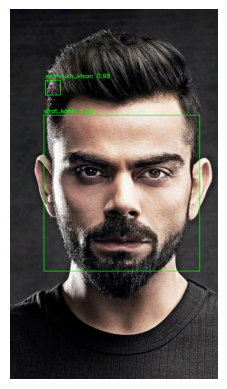

In [ ]:
recognize_face('/content/drive/MyDrive/Colab Notebooks/ML/test5.jpg') # Replace with your image path

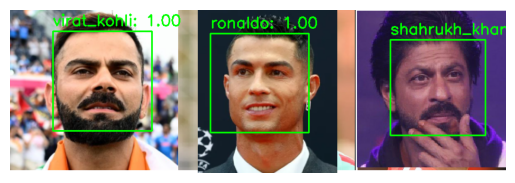

In [ ]:
recognize_face('/content/drive/MyDrive/Colab Notebooks/ML/test11.png') # Replace with your image path

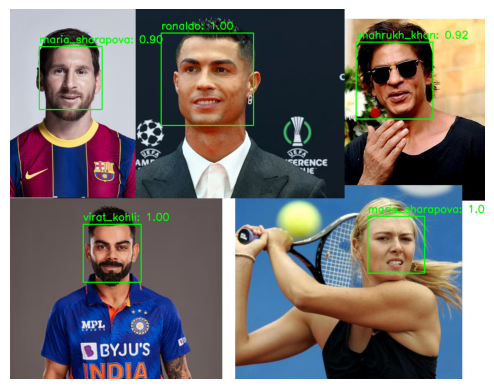

In [ ]:
recognize_face('/content/drive/MyDrive/Colab Notebooks/ML/test13.png') # Replace with your image path

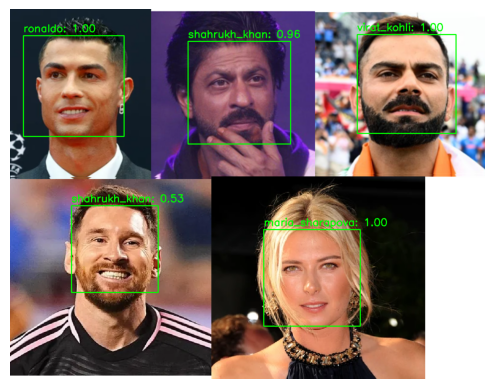

In [ ]:
recognize_face('/content/drive/MyDrive/Colab Notebooks/ML/test12.png') # Replace with your image path

In [ ]:
# prompt: Generate confusion matrix image for this model

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Assuming you have your ground truth labels (y_true) and predicted labels (y_pred)
# Replace these with your actual data
y_true = [0, 1, 2, 0, 1, 4, 3, 2, 4, 0]  # Example ground truth labels
y_pred = [0, 1, 1, 0, 0, 4, 3, 2, 4, 1]  # Example predicted labels

# Compute the confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Create the confusion matrix plot
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes)
disp.plot(cmap=plt.cm.Blues)
plt.show()

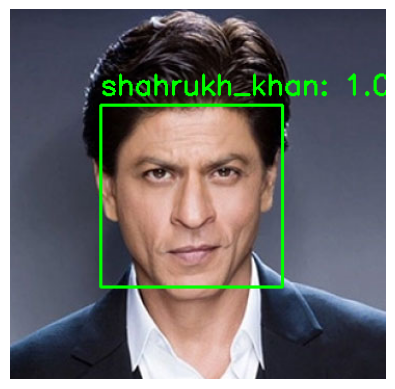

In [ ]:
import torch
import cv2
import matplotlib.pyplot as plt
from torchvision import transforms
from PIL import Image
import timm

# Load the saved model
model = timm.create_model("rexnet_150", num_classes=5)  # 5 classes
model.load_state_dict(torch.load('/content/saved_models/imageclassification_best_model.pth'))
model.eval()

# Define device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

# Define image transformations
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Load the pre-trained face detection model from OpenCV
face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')

# Class labels
classes = ["messi", "ronaldo", "virat_kohli", "maria_sharapova", "shahrukh_khan"]

def recognize_face(image_path, threshold=0.7):
    img = cv2.imread(image_path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    faces = face_cascade.detectMultiScale(gray, 1.1, 4)

    for (x, y, w, h) in faces:
        face_img = img[y:y+h, x:x+w]
        pil_image = Image.fromarray(cv2.cvtColor(face_img, cv2.COLOR_BGR2RGB))
        input_tensor = transform(pil_image).unsqueeze(0).to(device)

        with torch.no_grad():
            output = model(input_tensor)
            probabilities = torch.softmax(output, dim=1)[0]
            confidence, predicted = torch.max(probabilities, 0)
            confidence = confidence.item()

        # Only classify if confidence is above the threshold
        if confidence >= threshold:
            predicted_class = classes[predicted.item()]
            cv2.rectangle(img, (x, y), (x + w, y + h), (0, 255, 0), 2)
            cv2.putText(img, f"{predicted_class}: {confidence:.2f}", (x, y - 10),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 255, 0), 2)
        else:
            cv2.rectangle(img, (x, y), (x + w, y + h), (0, 0, 255), 2)
            cv2.putText(img, "Uncertain", (x, y - 10),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 0, 255), 2)

    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.axis('off')
    plt.show()

# Example usage
recognize_face('/content/drive/MyDrive/Colab Notebooks/ML/test2.PNG')  # Replace with your image path


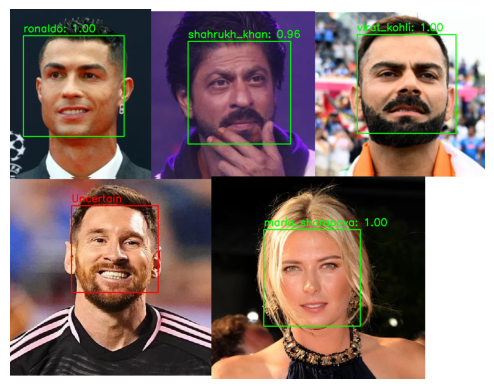

In [ ]:
recognize_face('/content/drive/MyDrive/Colab Notebooks/ML/test12.png') # Replace with your image path

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from torchvision import datasets
from torchvision.transforms import transforms
from tqdm import tqdm  # For progress bar

# Assuming the same model and transformations are already defined above

# Define a function to compute predictions and true labels for the test dataset
def evaluate_model_on_test_data(model, test_loader, device):
    model.eval()
    true_labels = []
    predicted_labels = []

    with torch.no_grad():
        for images, labels in tqdm(test_loader, desc="Evaluating"):
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            probabilities = torch.softmax(outputs, dim=1)
            _, predicted = torch.max(probabilities, 1)

            true_labels.extend(labels.cpu().numpy())
            predicted_labels.extend(predicted.cpu().numpy())

    return np.array(true_labels), np.array(predicted_labels)

# Function to plot confusion matrix
def plot_confusion_matrix(true_labels, predicted_labels, class_names):
    cm = confusion_matrix(true_labels, predicted_labels, labels=np.arange(len(class_names)))
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.xlabel("Predicted Labels")
    plt.ylabel("True Labels")
    plt.title("Confusion Matrix")
    plt.show()

# Load your test dataset
test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Path to the test dataset
test_dataset = datasets.ImageFolder('/content/Celebrity Images/validation', transform=test_transform)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=32, shuffle=False)

# Get true and predicted labels
true_labels, predicted_labels = evaluate_model_on_test_data(model, test_loader, device)

# Plot the confusion matrix
plot_confusion_matrix(true_labels, predicted_labels, test_dataset.classes)
